# 01 · EDA of MAMA-MIA for breast tumour segmentation
Goal: understand completeness, heterogeneity and tumour characteristics of the 1,506 DCE-MRI cases before training nnU-Net.


In [4]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("python:", sys.executable)


DATA_ROOT = Path(os.environ.get("MAMAMIA_ROOT", "/lustre/pd03/hpc-ljelen-1692966897/mamma_mia"))
OUT_DIR   = Path.home() / "zpi-eda" / "eda_out"   # all outputs go here
OUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_DIR  = DATA_ROOT / "images"
SEG_DIR  = DATA_ROOT / "segmentations" / "expert"
AUTO_DIR = DATA_ROOT / "segmentations" / "automatic"

print("patients (image dirs):", sum(p.is_dir() for p in IMG_DIR.iterdir()))
print("expert masks:         ", len(list(SEG_DIR.glob("*.nii.gz"))))
print("automatic masks:      ", len(list(AUTO_DIR.glob("*.nii.gz"))))

python: /home/kacjan7732/venvs/mamamia/bin/python3
patients (image dirs): 1506
expert masks:          1506
automatic masks:       1506


## 1. File inventory
Is the dataset complete, and do all patients have the same number of DCE phases? (nnU-Net needs a fixed number of input channels.)

In [5]:
import re

def collection_of(pid):
    for c in ("ISPY1", "ISPY2", "DUKE", "NACT"):
        if pid.startswith(c):
            return c
    return pid.split("_")[0]

phase_re = re.compile(r"_(\d{4})\.nii\.gz$")

rows = []
for d in sorted(p for p in IMG_DIR.iterdir() if p.is_dir()):
    pid = d.name.upper()                                   # image dirs: DUKE_001
    phases = sorted((int(phase_re.search(f.name).group(1)), str(f))
                    for f in d.glob("*.nii.gz") if phase_re.search(f.name))
    rows.append(dict(
        patient_id=pid,
        collection=collection_of(pid),
        n_phases=len(phases),
        phase_idx=[i for i, _ in phases],
        phase_files=[f for _, f in phases],
    ))
inv = pd.DataFrame(rows)

# mask filenames are lowercase (duke_001.nii.gz) -> normalise IDs to uppercase
seg_map  = {f.name.replace(".nii.gz", "").upper(): str(f) for f in SEG_DIR.glob("*.nii.gz")}
auto_map = {f.name.replace(".nii.gz", "").upper(): str(f) for f in AUTO_DIR.glob("*.nii.gz")}
inv["seg_file"]  = inv.patient_id.map(seg_map)
inv["auto_file"] = inv.patient_id.map(auto_map)

print("patients:", len(inv))
print("missing expert mask:", inv.seg_file.isna().sum())
print("masks without image:", sorted(set(seg_map) - set(inv.patient_id))[:10])
print("gaps in phase numbering:",
      inv[inv.phase_idx.apply(lambda l: l != list(range(len(l))))].patient_id.tolist()[:10])

pd.crosstab(inv.collection, inv.n_phases, margins=True)

patients: 1506
missing expert mask: 0
masks without image: []
gaps in phase numbering: []


n_phases,3,4,5,6,All
collection,,,,,
DUKE,4,159,128,0,291
ISPY1,143,15,0,13,171
ISPY2,0,1,8,971,980
NACT,58,4,1,1,64
All,205,179,137,985,1506


## 2. Clinical and acquisition metadata
Data comes from 4 collections, scanners and field strengths, i.e. a domain-shift risk for segmentation.
First we look at which metadata are available and how complete they are.

In [7]:
clin = pd.read_excel(DATA_ROOT / "clinical_and_imaging_info.xlsx", sheet_name=None)
print("sheets:", list(clin))

clin = clin["dataset_info"] if "dataset_info" in clin else next(iter(clin.values()))
clin["patient_id"] = clin["patient_id"].str.upper()
print("rows:", len(clin), "| matched to images:", clin.patient_id.isin(inv.patient_id).sum())

# one row per column: type, % missing, cardinality, example values
pd.DataFrame({
    "dtype": clin.dtypes.astype(str),
    "missing_%": (clin.isna().mean() * 100).round(1),
    "n_unique": clin.nunique(),
    "examples": clin.apply(lambda s: s.dropna().unique()[:4].tolist()),
})

sheets: ['dataset_info', 'legend']
rows: 1506 | matched to images: 1506


,dtype,missing_%,n_unique,examples
patient_id,str,0.0,1506,"[DUKE_001, DUKE_002, DUKE_005, DUKE_009]"
dataset,str,0.0,4,"[DUKE, ISPY1, ISPY2, NACT]"
bilateral_breast_cancer,int64,0.0,2,"[0, 1]"
multifocal_cancer,float64,10.6,2,"[0.0, 1.0]"
nac_agent,str,30.7,17,"[Paclitaxel + Ganitumab, Paclitaxel + Ganetesp..."
endocrine_therapy,float64,80.7,2,"[0.0, 1.0]"
anti_her2_neu_therapy,float64,80.7,2,"[1.0, 0.0]"
pcr,float64,1.0,2,"[0.0, 1.0]"
mastectomy_post_nac,float64,76.8,2,"[0.0, 1.0]"
days_to_follow_up,float64,65.7,456,"[2940.0, 1649.0, 1845.0, 1554.0]"


**Findings:** metadata cover all 1,506 cases. Imaging fields are complete, unlike clinical ones (up to 98% missing).
Notable for segmentation: both **axial and sagittal** acquisitions, **9 different phase counts**, 2 field strengths, 3 vendors / 22 scanner models.

In [9]:
IMAGING_COLS = [
    "patient_id", "dataset",
    # source / domain
    "manufacturer", "scanner_model", "field_strength",
    # geometry
    "view", "bilateral_mri", "image_rows", "image_columns", "num_slices", "pixel_spacing", "slice_thickness",
    # protocol
    "num_phases", "acquisition_times", "fat_suppressed", "echo_time", "repetition_time",
    # content that affects image / mask appearance
    "has_implant", "multifocal_cancer", "bilateral_breast_cancer",
]
img_meta = clin[IMAGING_COLS].copy()

# pixel_spacing is stored as a string "[x, y]" -> two float columns
ps = img_meta.pixel_spacing.str.strip("[]").str.split(",", expand=True).astype(float)
img_meta["spacing_x"], img_meta["spacing_y"] = ps[0], ps[1]
img_meta = img_meta.drop(columns="pixel_spacing")

# strip trailing spaces in scanner names ("Skyra " vs "Skyra")
img_meta["scanner_model"] = img_meta.scanner_model.str.strip()

img_meta.groupby("dataset").agg(
    n=("patient_id", "size"),
    vendors=("manufacturer", lambda s: ", ".join(sorted(s.unique()))),
    field_T=("field_strength", lambda s: ", ".join(map(str, sorted(s.unique())))),
    views=("view", lambda s: ", ".join(sorted(s.unique()))),
    phases=("num_phases", lambda s: f"{s.min()}–{s.max()}"),
    spacing_xy_mm=("spacing_x", "median"),
    slice_mm=("slice_thickness", "median"),
    implants=("has_implant", "sum"),
).round(2)

,n,vendors,field_T,views,phases,spacing_xy_mm,slice_mm,implants
dataset,,,,,,,,
DUKE,291,"GE, SIEMENS","1.5, 3.0",axial,3–6,0.70,1.0,0
ISPY1,171,"GE, Philips, SIEMENS",1.5,sagittal,3–6,0.78,2.3,1
ISPY2,980,"GE, Philips, SIEMENS","1.5, 3.0",axial,4–11,0.68,2.0,29
NACT,64,GE,1.5,sagittal,3–7,0.70,2.0,0


### 2.1 How different are the collections?
A model trained on mixed sources can silently underperform on one of them; we visualise where they differ.

In [13]:
DATASETS = ["DUKE", "ISPY1", "ISPY2", "NACT"]

def count_panel(ax, col, title, labels=None):
    """Grouped bar chart: cases per collection, split by the values of `col`."""
    data = img_meta.assign(**{col: img_meta[col].map(labels) if labels else img_meta[col].astype(str)})
    sns.countplot(data=data, x="dataset", hue=col, order=DATASETS, palette="Set2", ax=ax)
    for c in ax.containers:  # print counts on bars, hide zeros
        ax.bar_label(c, labels=[int(v) if v > 0 else "" for v in c.datavalues], fontsize=9)
    ax.set_title(title, fontsize=12); ax.set_xlabel(""); ax.set_ylabel("cases")
    ax.legend(title=None, frameon=False, loc="upper right")

In [22]:
def percent_panel(ax, col, title, labels=None, colors=None):
    """100% stacked columns: share of each value of `col` within every collection.
    colors: list or {value: color} dict; defaults to Set2."""
    vals = img_meta[col].map(labels) if labels else img_meta[col].astype(str)
    pct = pd.crosstab(img_meta.dataset, vals, normalize="index").reindex(DATASETS) * 100
    n = img_meta.dataset.value_counts().reindex(DATASETS)

    if isinstance(colors, dict):
        colors = [colors[c] for c in pct.columns]
    colors = colors or sns.color_palette("Set2", pct.shape[1])

    pct.plot.bar(stacked=True, ax=ax, color=colors, width=0.7, rot=0, edgecolor="white")
    for c in ax.containers:  # % inside segments, skip tiny ones
        ax.bar_label(c, labels=[f"{v:.0f}%" if v >= 5 else "" for v in c.datavalues],
                     label_type="center", fontsize=9, color="white", fontweight="bold")
    ax.set_xticklabels([f"{d}\n(n={n[d]})" for d in DATASETS])
    ax.set_title(title, fontsize=12); ax.set_xlabel(""); ax.set_ylabel("% of cases"); ax.set_ylim(0, 100)
    ax.legend(title=None, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=pct.shape[1])

### 2.1 Who acquired the images?
Vendor and field strength change contrast and noise, the classic sources of domain shift.

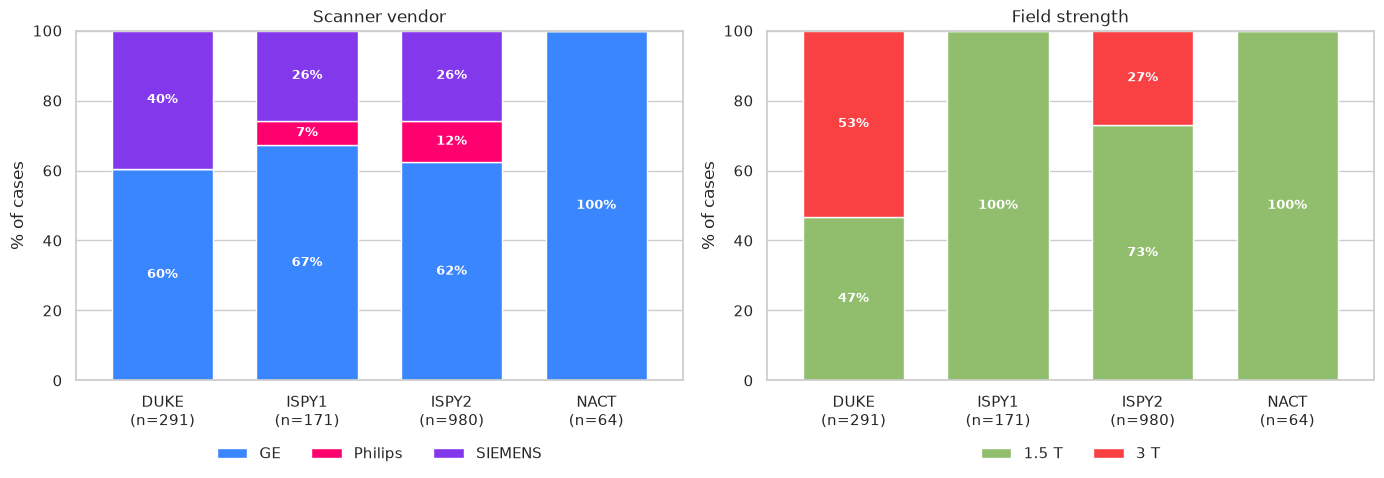

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
percent_panel(axes[0], "manufacturer", "Scanner vendor",
              colors={"GE": "#3A86FF", "SIEMENS": "#8338EC", "Philips": "#FF006E"})
percent_panel(axes[1], "field_strength", "Field strength",
              labels={1.5: "1.5 T", 3.0: "3 T"},
              colors={"1.5 T": "#90BE6D", "3 T": "#F94144"})
plt.tight_layout(); plt.savefig(OUT_DIR / "02_vendor_field.png", dpi=150, bbox_inches="tight"); plt.show()

### 2.2 How were the breasts imaged?
Orientation and single- vs both-breast field of view change the image geometry the model sees.

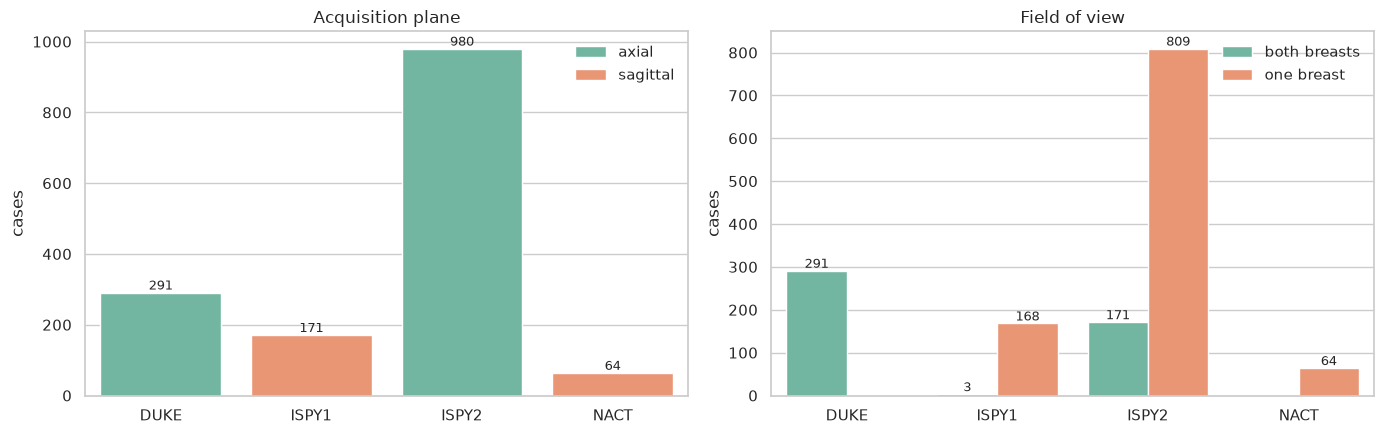

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
count_panel(axes[0], "view", "Acquisition plane")
count_panel(axes[1], "bilateral_mri", "Field of view", labels={0: "one breast", 1: "both breasts"})
plt.tight_layout(); plt.savefig(OUT_DIR / "02_view_fov.png", dpi=150, bbox_inches="tight"); plt.show()

### 2.3 How many DCE phases do we get?
nnU-Net needs a fixed number of input channels, so the smallest common phase count matters.

In [26]:
# cases per collection x number of phases (empty = no such cases)
ph = pd.crosstab(img_meta.dataset, img_meta.num_phases, margins=True, margins_name="total")
ph.replace(0, "").rename_axis(index=None, columns="phases →")

phases →,3,4,5,6,7,8,9,10,11,total
DUKE,4,159,125,3,,,,,,291
ISPY1,143,15,,13,,,,,,171
ISPY2,,1,8,181,469,280,39,1,1,980
NACT,58,4,1,,1,,,,,64
total,205,179,134,197,470,280,39,1,1,1506


In [33]:
# if the model takes the first k phases, how many cases have them ON DISK?
k_range = range(2, 7)
coverage = pd.DataFrame({
    f"≥{k} phases": inv.groupby("collection").n_phases.apply(lambda s: (s >= k).mean() * 100)
    for k in k_range
}).reindex(DATASETS)
coverage.loc["all"] = [(inv.n_phases >= k).mean() * 100 for k in k_range]
coverage.round(1).astype(str) + "%"

,≥2 phases,≥3 phases,≥4 phases,≥5 phases,≥6 phases
collection,,,,,
DUKE,100.0%,100.0%,98.6%,44.0%,0.0%
ISPY1,100.0%,100.0%,16.4%,7.6%,7.6%
ISPY2,100.0%,100.0%,100.0%,99.9%,99.1%
NACT,100.0%,100.0%,9.4%,3.1%,1.6%
all,100.0%,100.0%,86.4%,74.5%,65.4%


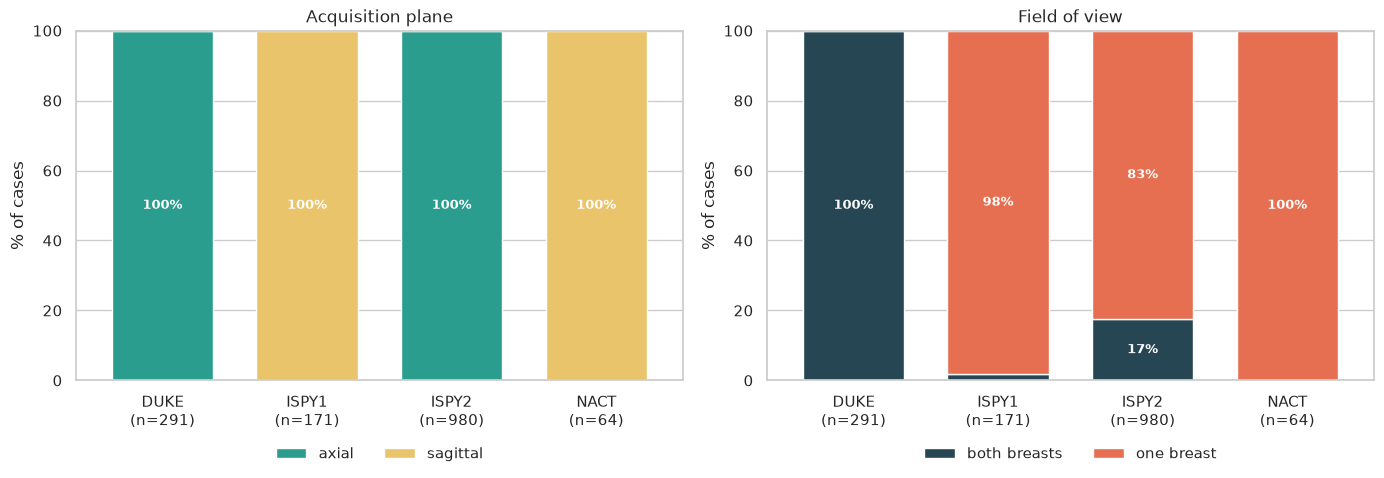

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
percent_panel(axes[0], "view", "Acquisition plane",
              colors={"axial": "#2A9D8F", "sagittal": "#E9C46A"})
percent_panel(axes[1], "bilateral_mri", "Field of view",
              labels={0: "one breast", 1: "both breasts"},
              colors={"one breast": "#E76F51", "both breasts": "#264653"})
plt.tight_layout(); plt.savefig(OUT_DIR / "02_view_fov.png", dpi=150, bbox_inches="tight"); plt.show()

### 2.4 Image geometry
Voxel size and matrix size decide the resampling target and the patch size nnU-Net can fit into GPU memory.

In [29]:
# median [min–max] per collection: compact enough to read at a glance
def med_range(s):
    return f"{s.median():.2f} [{s.min():.2f}–{s.max():.2f}]"

geo = img_meta.groupby("dataset").agg(
    spacing_xy_mm=("spacing_x", med_range),
    slice_mm=("slice_thickness", med_range),
    rows=("image_rows", lambda s: f"{int(s.median())} [{s.min()}–{s.max()}]"),
    slices=("num_slices", lambda s: f"{int(s.median())} [{s.min()}–{s.max()}]"),
).reindex(DATASETS)
geo

,spacing_xy_mm,slice_mm,rows,slices
dataset,,,,
DUKE,0.70 [0.53–1.25],1.00 [1.00–2.50],512 [320–512],170 [60–256]
ISPY1,0.78 [0.39–1.17],2.30 [1.50–4.00],256 [256–512],60 [44–256]
ISPY2,0.68 [0.31–1.41],2.00 [0.80–3.00],512 [256–1024],80 [52–256]
NACT,0.70 [0.35–0.90],2.00 [2.00–2.40],256 [256–512],60 [46–64]


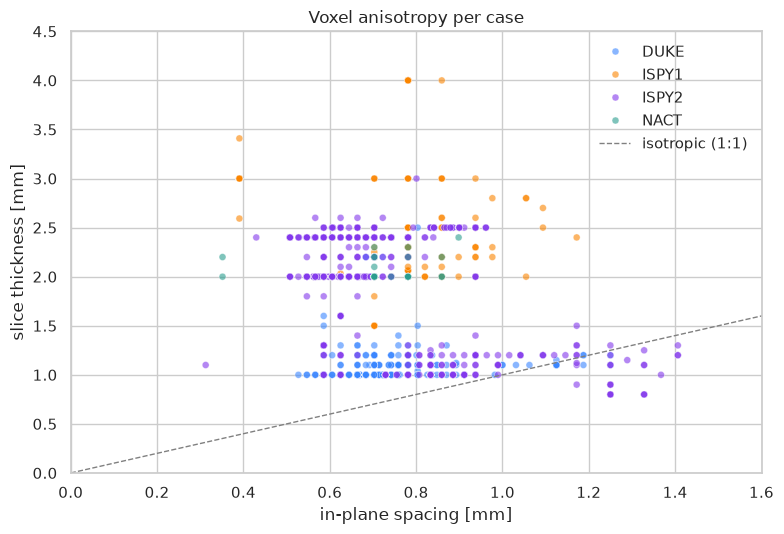

anisotropy ratio (slice / in-plane), median per collection: {'DUKE': 1.5, 'ISPY1': 2.8, 'ISPY2': 3.1, 'NACT': 2.8}


In [34]:
# how "flat" are the voxels? slice thickness vs in-plane spacing, one dot per case
fig, ax = plt.subplots(figsize=(8, 5.5))
pal = {"DUKE": "#3A86FF", "ISPY1": "#FB8500", "ISPY2": "#8338EC", "NACT": "#2A9D8F"}
sns.scatterplot(data=img_meta, x="spacing_x", y="slice_thickness", hue="dataset",
                hue_order=DATASETS, palette=pal, alpha=0.6, s=25, ax=ax)
lim = [0, max(img_meta.spacing_x.max(), img_meta.slice_thickness.max()) * 1.05]
ax.plot(lim, lim, ls="--", c="grey", lw=1, label="isotropic (1:1)")
ax.set_xlabel("in-plane spacing [mm]"); ax.set_ylabel("slice thickness [mm]")
ax.set_title("Voxel anisotropy per case"); ax.legend(frameon=False)
ax.set_xlim(0, 1.6); ax.set_ylim(0, 4.5)
plt.tight_layout(); plt.savefig(OUT_DIR / "02_anisotropy.png", dpi=150, bbox_inches="tight"); plt.show()

ratio = img_meta.slice_thickness / img_meta.spacing_x
print("anisotropy ratio (slice / in-plane), median per collection:",
      ratio.groupby(img_meta.dataset).median().round(1).to_dict())

**Findings:** in-plane spacing is similar everywhere (~0.5–1.4 mm); collections differ mainly in **slice thickness** (~1 mm DUKE vs 2–3 mm ISPY1/NACT/most ISPY2).
Voxels are 1.5–3× anisotropic; resampling thick-slice cases to ~1 mm in z means interpolating, so expect weaker boundaries along z.
→ Report segmentation metrics separately for thin- and thick-slice cases.

### 2.5 Do metadata agree with the files on disk?
Metadata are only useful if they describe the actual files; we cross-check the phase count.

In [32]:
check = inv[["patient_id", "n_phases"]].merge(img_meta[["patient_id", "num_phases"]], on="patient_id")
mismatch = check[check.n_phases != check.num_phases]
print(f"phase count mismatch (files vs metadata): {len(mismatch)} / {len(check)}")
mismatch.head(10)

phase count mismatch (files vs metadata): 794 / 1506


,patient_id,n_phases,num_phases
136,DUKE_406,5,6
156,DUKE_470,5,6
248,DUKE_775,5,6
462,ISPY2_100899,6,8
463,ISPY2_102011,6,7
464,ISPY2_102212,6,8
465,ISPY2_103693,6,8
466,ISPY2_103939,6,7
467,ISPY2_104268,6,8
468,ISPY2_104384,6,8


In [35]:
# direction and pattern of the mismatch
diff = check.num_phases - check.n_phases
print("files > metadata:", (diff < 0).sum(), "| files < metadata:", (diff > 0).sum())
print("max phases on disk per collection:",
      check.assign(dataset=check.patient_id.map(collection_of))
           .groupby("dataset").n_phases.max().to_dict())

# phases on disk (rows) vs phases in metadata (columns)
pd.crosstab(check.n_phases, check.num_phases).rename_axis(index="on disk", columns="metadata")

files > metadata: 0 | files < metadata: 794
max phases on disk per collection: {'DUKE': 5, 'ISPY1': 6, 'ISPY2': 6, 'NACT': 6}


metadata,3,4,5,6,7,8,9,10,11
on disk,,,,,,,,,
3,205,0,0,0,0,0,0,0,0
4,0,179,0,0,0,0,0,0,0
5,0,0,134,3,0,0,0,0,0
6,0,0,0,194,470,280,39,1,1


**Findings:** `num_phases` describes the original acquisition; the release keeps **at most 6 phases** (pre + 5 post), so 794 cases were truncated.
On disk every case has **≥ 3 phases** → pre + 2 post-contrast is the largest input that covers 100% of cases without padding.

**Section 2 summary:** collections differ in vendor, field strength, **plane (ISPY1/NACT sagittal)** and **slice thickness (1 vs 2–3 mm)**.
Use phase counts from disk, not metadata; evaluate per collection and per slice-thickness group.

## 3. Tumour masks
How big are the tumours, how many lesions per case, and does each mask actually align with its image?

In [36]:
from concurrent.futures import ProcessPoolExecutor
from scipy import ndimage
from tqdm.auto import tqdm

def mask_stats(row):
    """Per-case stats from the image HEADER (no voxel loading) and the full expert mask."""
    out = {"patient_id": row["patient_id"]}
    try:
        img = nib.load(row["phase_files"][0])          # header only, data not read
        seg = nib.load(row["seg_file"])
        sp = img.header.get_zooms()[:3]
        out.update(shape=img.shape[:3], orientation="".join(nib.aff2axcodes(img.affine)),
                   sp_x=sp[0], sp_y=sp[1], sp_z=sp[2],
                   seg_shape_ok=seg.shape[:3] == img.shape[:3],
                   seg_affine_ok=bool(np.allclose(seg.affine, img.affine, atol=1e-3)))

        m = np.asanyarray(seg.dataobj)
        out["labels"] = ",".join(map(str, np.unique(m).astype(int)))
        m = m > 0
        nvox = int(m.sum())
        out["tumor_ml"] = nvox * float(np.prod(sp)) / 1000
        out["tumor_frac"] = nvox / m.size                # share of the whole volume -> class imbalance
        if nvox:
            lab, ncc = ndimage.label(m, structure=np.ones((3, 3, 3)))
            sizes = np.bincount(lab.ravel())[1:]
            out["n_lesions"] = ncc
            out["largest_lesion_frac"] = sizes.max() / nvox
            idx = np.argwhere(m)
            ext = (idx.max(0) - idx.min(0) + 1) * np.array(sp)
            out["max_extent_mm"] = float(ext.max())
            out.update({f"centroid_{a}": c for a, c in zip("xyz", idx.mean(0) / np.array(m.shape))})
    except Exception as e:
        out["error"] = f"{type(e).__name__}: {e}"
    return out

CACHE = OUT_DIR / "mask_stats.csv"
if CACHE.exists():
    ms = pd.read_csv(CACHE)            # computed once, reused on every rerun
else:
    with ProcessPoolExecutor(max_workers=8) as ex:
        ms = pd.DataFrame(list(tqdm(ex.map(mask_stats, inv.to_dict("records"), chunksize=8), total=len(inv))))
    ms.to_csv(CACHE, index=False)

ms = ms.merge(inv[["patient_id", "collection"]], on="patient_id")
print("errors:", ms.error.notna().sum() if "error" in ms else 0)
print("geometry mismatch image vs mask:", (~(ms.seg_shape_ok & ms.seg_affine_ok)).sum())
print("label values:", ms.labels.value_counts().to_dict())
print("orientations:", ms.orientation.value_counts().to_dict())

/home/kacjan7732/venvs/mamamia/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████████████████████████████████████████████████████████████████████████| 1506/1506 [03:57<00:00,  6.33it/s]

errors: 0
geometry mismatch image vs mask: 0
label values: {'0,1': 1506}
orientations: {'LAI': 1271, 'PSL': 235}


**Findings:** all 1,506 masks are binary, non-empty and geometrically aligned with their images → no case needs to be excluded.
Two array orientations: `LAI` (axial collections) and `PSL` (sagittal ISPY1 + NACT), so spatial analyses must be split by orientation.

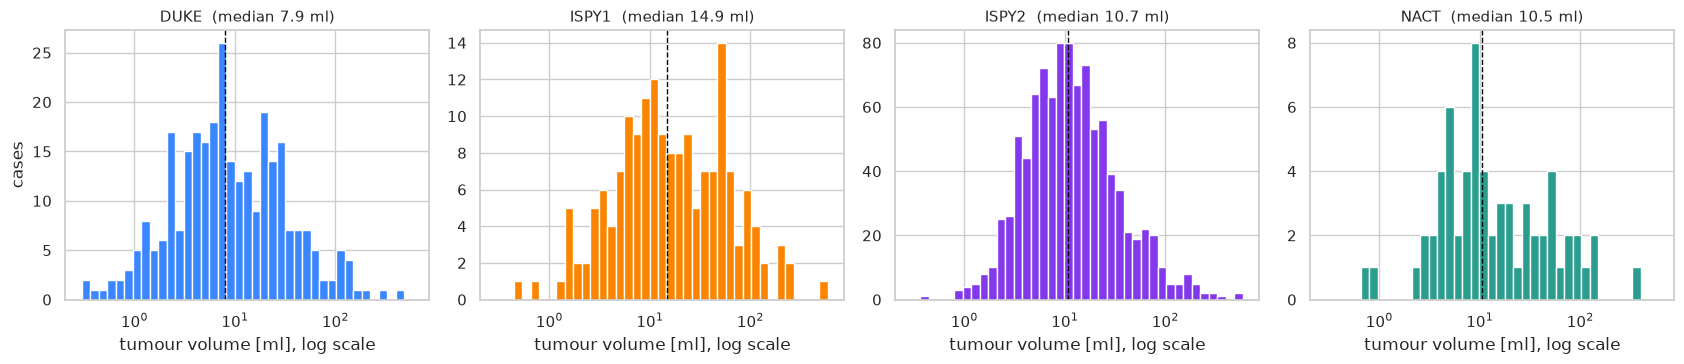

In [37]:
pal = {"DUKE": "#3A86FF", "ISPY1": "#FB8500", "ISPY2": "#8338EC", "NACT": "#2A9D8F"}
bins = np.logspace(np.log10(ms.tumor_ml.min()), np.log10(ms.tumor_ml.max()), 40)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharex=True)
for ax, ds in zip(axes, DATASETS):
    v = ms.loc[ms.collection == ds, "tumor_ml"]
    ax.hist(v, bins=bins, color=pal[ds], edgecolor="white")
    ax.axvline(v.median(), color="black", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_title(f"{ds}  (median {v.median():.1f} ml)", fontsize=11)
    ax.set_xlabel("tumour volume [ml], log scale")
axes[0].set_ylabel("cases")
plt.tight_layout(); plt.savefig(OUT_DIR / "03_tumour_volume.png", dpi=150, bbox_inches="tight"); plt.show()

**Findings:** tumour volume is log-normal and spans ~3 orders of magnitude (≈0.3–500 ml); medians 8–15 ml (NAC cohorts, locally advanced cancers).
DUKE has the smallest tumours, ISPY1 the largest → mean Dice will be driven by large lesions, so report it **per size bin** too.

In [38]:
# fixed, clinically interpretable size bins (not quantiles), so they mean the same across collections
size_bins = [0, 1, 5, 20, np.inf]
size_lbl  = ["<1 ml", "1–5 ml", "5–20 ml", ">20 ml"]
ms["size_bin"] = pd.cut(ms.tumor_ml, size_bins, labels=size_lbl)

pd.crosstab(ms.collection, ms.size_bin, margins=True, margins_name="total").reindex(DATASETS + ["total"])

size_bin,<1 ml,1–5 ml,5–20 ml,>20 ml,total
collection,,,,,
DUKE,12,86,112,81,291
ISPY1,2,25,71,73,171
ISPY2,4,205,505,266,980
NACT,2,14,25,23,64
total,20,330,713,443,1506


Only 20 tumours are < 1 ml (12 in DUKE) → too few for a stable metric; for evaluation we merge them into **3 bins: < 5 / 5–20 / > 20 ml** (350 / 713 / 443 cases).

In [40]:
# within ONE cohort (ISPY2: same trial, both thin and thick slices) does slice thickness change measured volume?
isp2 = ms[ms.collection == "ISPY2"].assign(
    slices=lambda d: pd.cut(d.sp_z, [0, 1.6, np.inf], labels=["thin (≤1.6 mm)", "thick (>1.6 mm)"]))
isp2.groupby("slices", observed=True).tumor_ml.describe(percentiles=[.25, .5, .75]).round(1)

,count,mean,std,min,25%,50%,75%,max
slices,,,,,,,,
thin (≤1.6 mm),385.0,22.2,45.5,0.4,5.5,9.9,19.4,587.5
thick (>1.6 mm),595.0,22.5,39.5,0.8,5.7,11.2,22.9,566.6


Within ISPY2, thin- vs thick-slice cases have similar median volume → collection differences reflect mostly cohort selection, not acquisition.

### 3.2 How many separate lesions does a mask contain?
Multi-lesion masks need lesion-level metrics; a single voxel Dice hides a missed satellite lesion.

In [43]:
# connected components in the expert mask (26-connectivity)
ms["lesion_bin"] = pd.cut(ms.n_lesions, [0, 1, 5, np.inf], labels=["1", "2–5", ">5"])
les = pd.crosstab(ms.collection, ms.lesion_bin, normalize="index").reindex(DATASETS) * 100
les["median largest-lesion share"] = ms.groupby("collection").largest_lesion_frac.median().reindex(DATASETS) * 100
les.round(1)

lesion_bin,1,2–5,>5,median largest-lesion share
collection,,,,
DUKE,29.2,18.2,52.6,99.9
ISPY1,57.9,28.7,13.5,100.0
ISPY2,62.9,28.3,8.9,100.0
NACT,78.1,21.9,0.0,100.0


**Findings:** many masks have several components (DUKE: 53% with >5), yet the largest one holds ~100% of the volume → extra components are mostly tiny fragments.

In [46]:
# volume outside the largest component: tiny specks vs real satellite lesions
ms["satellite_ml"] = ms.tumor_ml * (1 - ms.largest_lesion_frac)
ms["has_real_satellite"] = ms.satellite_ml > 0.1          # > 0.1 ml ≈ a lesion of ~6 mm diameter

sat = ms.merge(img_meta[["patient_id", "multifocal_cancer"]], on="patient_id")
pd.DataFrame({
    "masks with >1 component [%]":      sat.groupby("collection").n_lesions.apply(lambda s: (s > 1).mean() * 100),
    "masks with satellite >0.1 ml [%]": sat.groupby("collection").has_real_satellite.mean() * 100,
    "clinically multifocal [%]":        sat.groupby("collection").multifocal_cancer.mean() * 100,
}).reindex(DATASETS).round(1)

,masks with >1 component [%],masks with satellite >0.1 ml [%],clinically multifocal [%]
collection,,,
DUKE,70.8,20.3,47.8
ISPY1,42.1,16.4,36.4
ISPY2,37.1,14.5,39.7
NACT,21.9,6.2,10.9


**Findings:** only 6–20% of masks contain a real satellite (>0.1 ml), fewer than the clinically multifocal rate (11–48%) → masks mainly capture the dominant lesion.
→ Do **not** apply "keep largest component" post-processing blindly; for lesion-level metrics ignore components < 0.1 ml.

### 3.3 How small is the tumour relative to the whole image?
Extreme foreground/background imbalance drives the choice of loss function and patch sampling.

In [48]:
# tumour voxels as % of the whole volume = what a random patch would "see"
imb = ms.groupby("collection").tumor_frac.describe(percentiles=[.05, .5, .95]).reindex(DATASETS)
imb = (imb[["5%", "50%", "95%"]] * 100).round(3).add_suffix(" [% of volume]")
imb["1 tumour voxel per … voxels (median)"] = (1 / ms.groupby("collection").tumor_frac.median()).reindex(DATASETS).round(0).astype(int)
imb

,5% [% of volume],50% [% of volume],95% [% of volume],1 tumour voxel per … voxels (median)
collection,,,,
DUKE,0.005,0.039,0.389,2569
ISPY1,0.035,0.253,2.255,395
ISPY2,0.031,0.185,1.510,542
NACT,0.065,0.259,2.599,387


**Findings:** tumour is a tiny fraction of the volume: median ~0.2% (1 voxel in ~400–550) and **0.04% in DUKE (1 in ~2,600)**, because of bilateral FOV and smaller tumours.
→ nnU-Net's defaults (Dice + CE loss, forced foreground patch sampling) are needed; cropping to the breast region would help DUKE most.

### 3.4 Where in the image are the tumours?
If tumours occupy a predictable region, we can crop images safely; we check per orientation since axes differ.

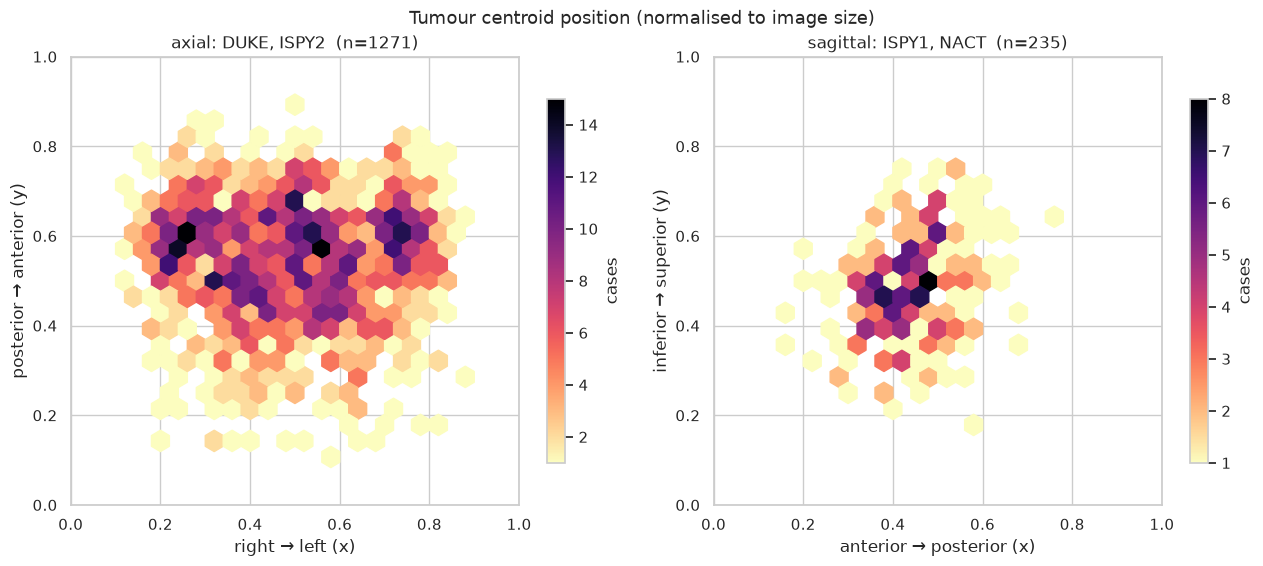

In [51]:
# normalised tumour centroid in the in-plane axes; LAI (axial) and PSL (sagittal) plotted separately
# axis codes give the direction each array axis INCREASES toward (LAI: x→Left, y→Anterior; PSL: x→Posterior, y→Superior)
views = {
    "LAI": ("centroid_x", "centroid_y", "right → left (x)", "posterior → anterior (y)", "axial: DUKE, ISPY2"),
    "PSL": ("centroid_x", "centroid_y", "anterior → posterior (x)", "inferior → superior (y)", "sagittal: ISPY1, NACT"),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (orient, (cx, cy, xl, yl, title)) in zip(axes, views.items()):
    d = ms[ms.orientation == orient]
    hb = ax.hexbin(d[cx], d[cy], gridsize=25, extent=(0, 1, 0, 1), cmap="magma_r", mincnt=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(f"{title}  (n={len(d)})")
    fig.colorbar(hb, ax=ax, label="cases", shrink=.8)
fig.suptitle("Tumour centroid position (normalised to image size)", fontsize=13)
plt.tight_layout(); plt.savefig(OUT_DIR / "03_centroids.png", dpi=150, bbox_inches="tight"); plt.show()

**Findings:** tumours never lie in the outer ~10% of the image and rarely in the posterior (chest-wall) part; sagittal ones cluster in the anterior-central breast.
→ Cropping to the breast region is safe and would cut background, but centroid maps alone don't justify a fixed crop box; leave it to nnU-Net's own cropping.

### 3.5 What do the images and masks actually look like?
Statistics can hide broken cases; we look at the smallest, median and largest tumour, plus one random case per collection.

▶ smallest


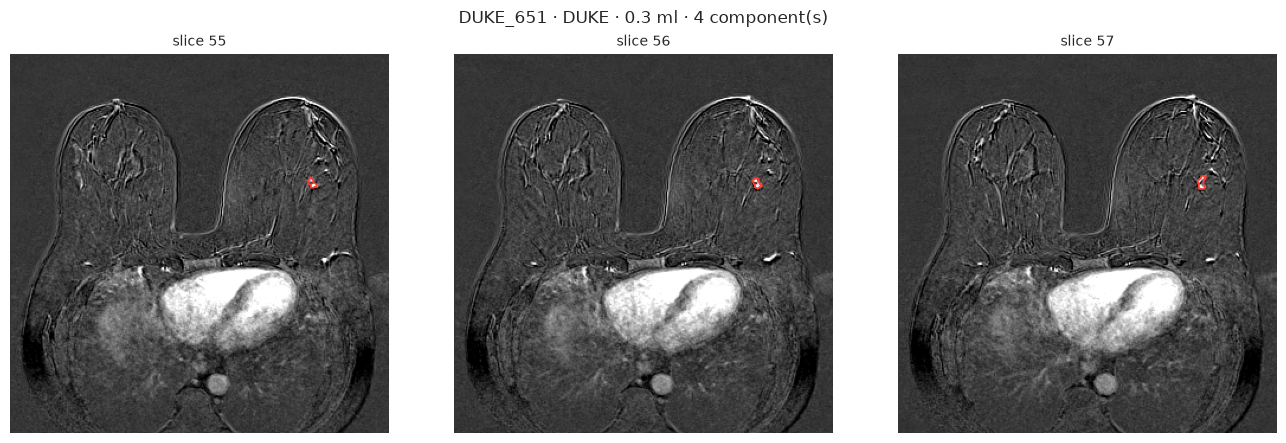

▶ median


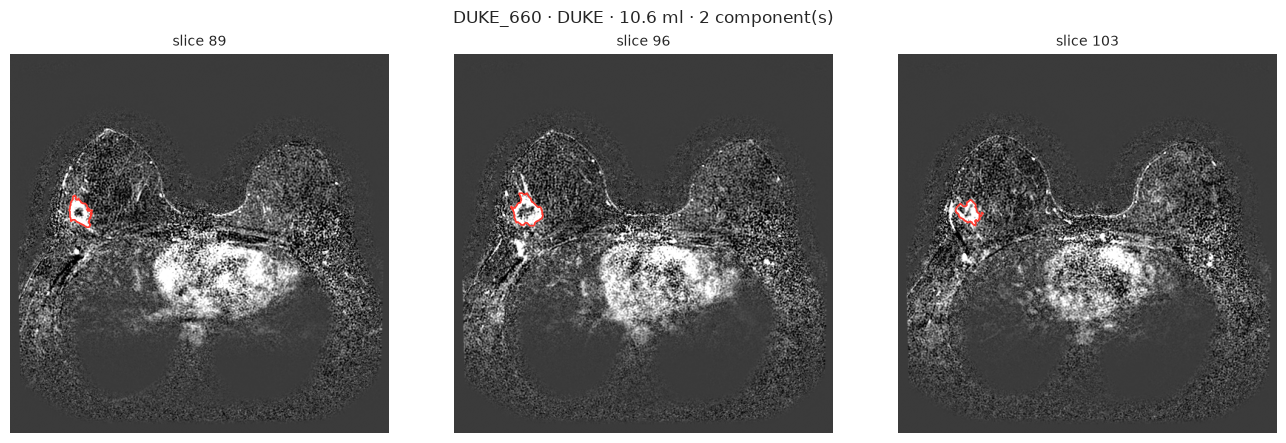

▶ largest


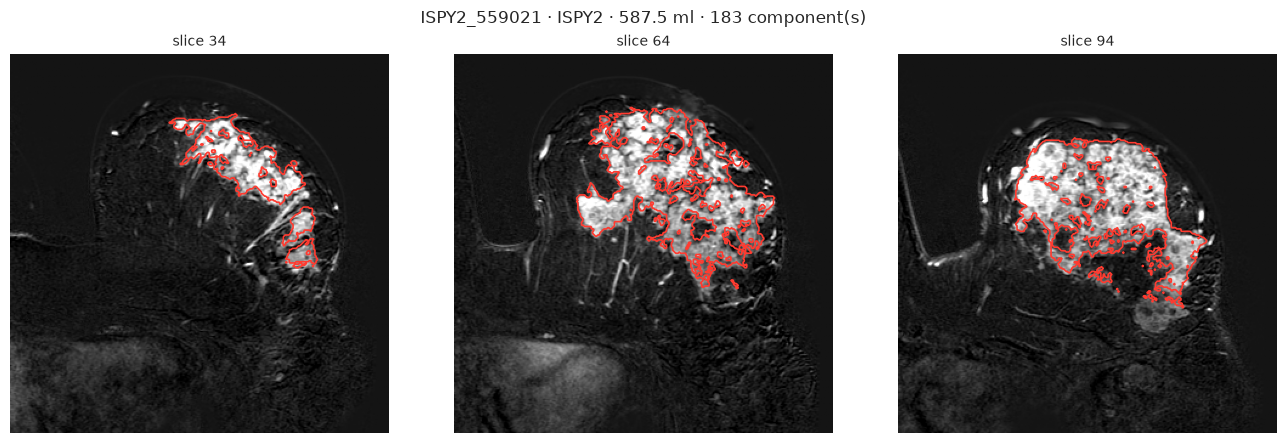

In [53]:
def show_case(pid, n_slices=3):
    """Subtraction image (1st post − pre) with the expert mask contour on slices through the tumour."""
    r = inv.set_index("patient_id").loc[pid]
    pre  = np.asanyarray(nib.load(r.phase_files[0]).dataobj).astype(np.float32)
    post = np.asanyarray(nib.load(r.phase_files[1]).dataobj).astype(np.float32)
    sub = post - pre                                   # enhancement = what radiologists look at
    m = np.asanyarray(nib.load(r.seg_file).dataobj) > 0

    z = np.flatnonzero(m.any(axis=(0, 1)))             # slices along the 3rd array axis that contain tumour
    sl = np.unique(np.linspace(z.min(), z.max(), n_slices + 2)[1:-1].astype(int))
    lo, hi = np.percentile(sub, [1, 99.5])

    fig, axes = plt.subplots(1, len(sl), figsize=(4.5 * len(sl), 4.5))
    for a, s in zip(np.atleast_1d(axes), sl):
        a.imshow(np.rot90(sub[:, :, s]), cmap="gray", vmin=lo, vmax=hi)
        a.contour(np.rot90(m[:, :, s]), levels=[.5], colors="#FF3B30", linewidths=1.2)
        a.set_title(f"slice {s}", fontsize=10); a.axis("off")
    row = ms.set_index("patient_id").loc[pid]
    fig.suptitle(f"{pid} · {row.collection} · {row.tumor_ml:.1f} ml · {int(row.n_lesions)} component(s)", fontsize=12)
    plt.tight_layout(); plt.show()

srt = ms.sort_values("tumor_ml")
picks = {"smallest": srt.patient_id.iloc[0], "median": srt.patient_id.iloc[len(srt) // 2], "largest": srt.patient_id.iloc[-1]}
for name, pid in picks.items():
    print(f"▶ {name}"); show_case(pid)

▶ random DUKE


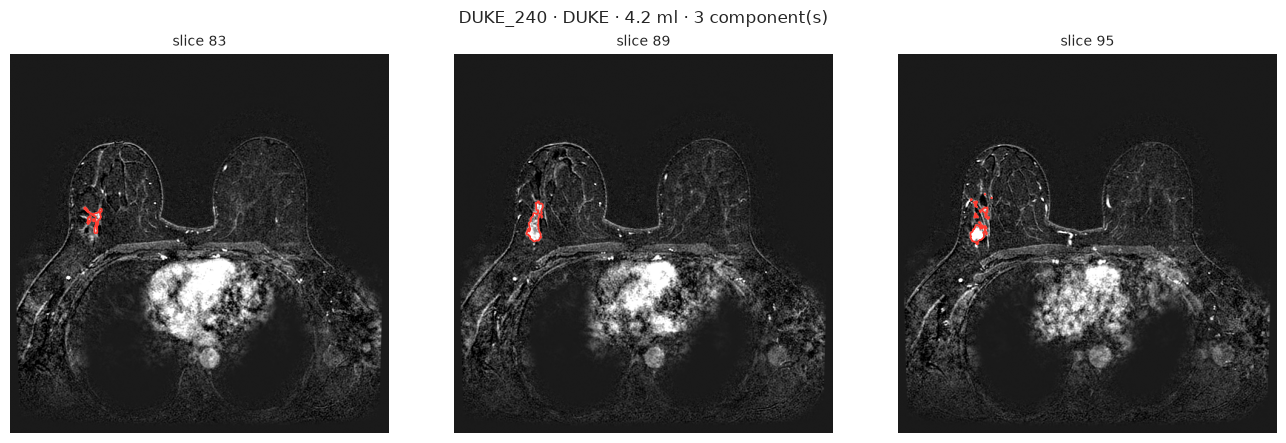

▶ random ISPY1


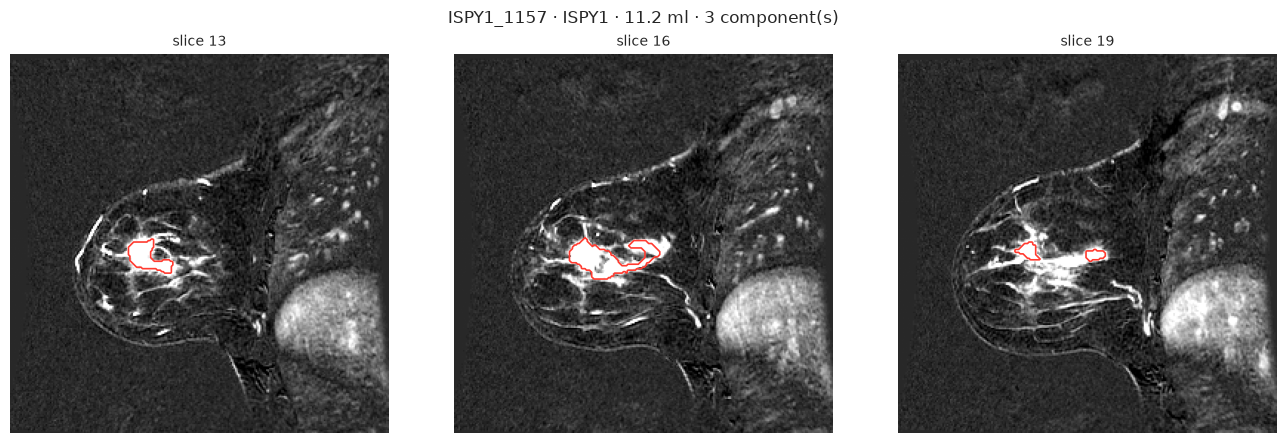

▶ random ISPY2


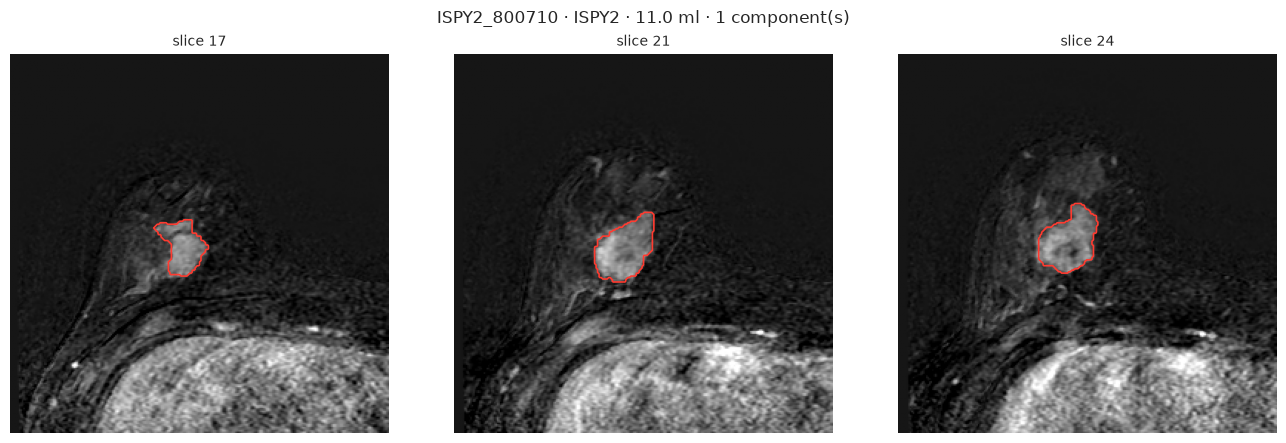

▶ random NACT


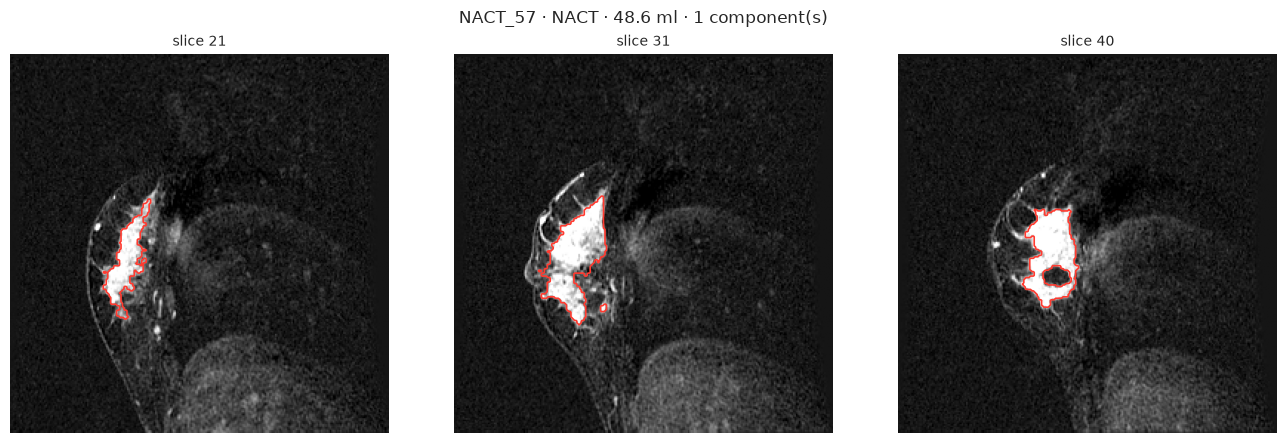

In [54]:
# one random case per collection, fixed seed so the notebook is reproducible
for ds in DATASETS:
    pid = ms[ms.collection == ds].sample(1, random_state=42).patient_id.iloc[0]
    print(f"▶ random {ds}"); show_case(pid)

### 3.6 Expert vs automatic masks
MAMA-MIA also ships masks from the authors' nnU-Net; comparing them voxel by voxel shows where a model typically fails.
Green = both agree, red = expert only (missed by model), blue = model only (false positive).

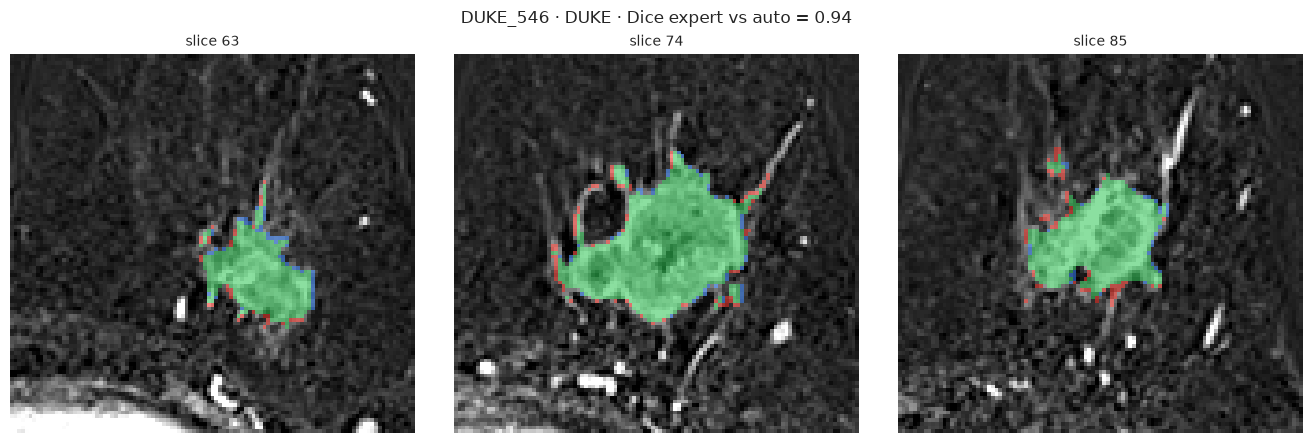

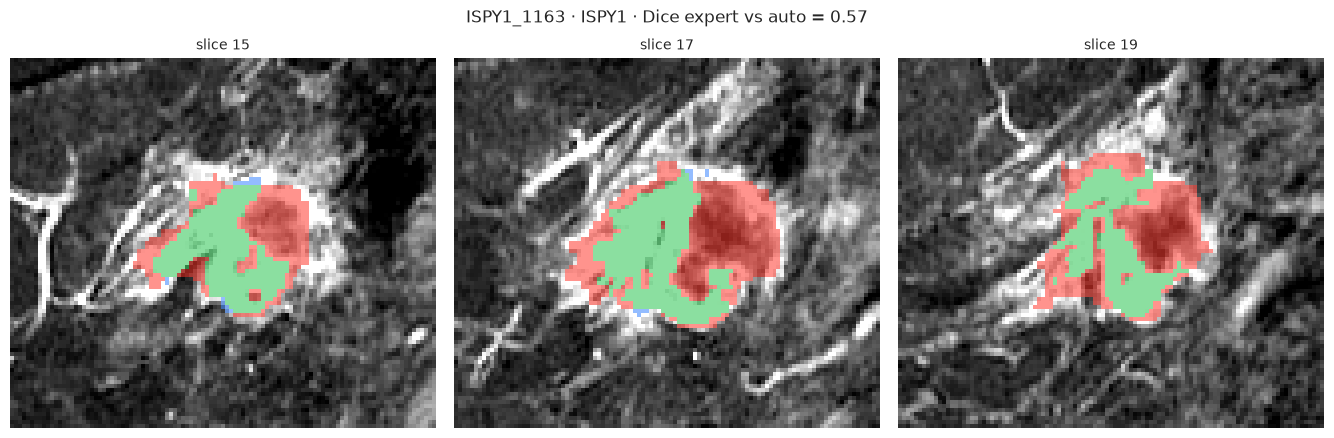

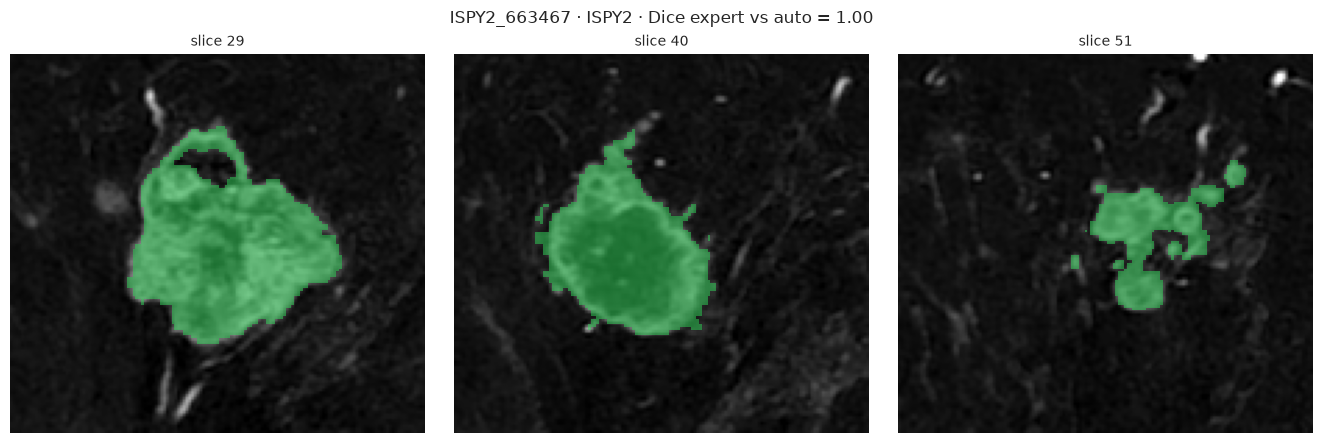

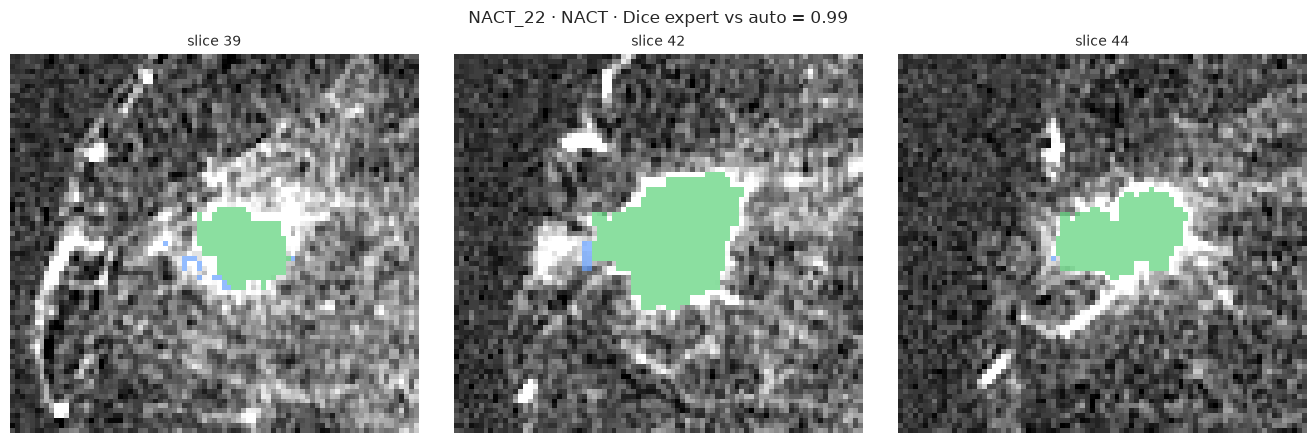

In [68]:
from matplotlib.colors import ListedColormap
AGREE_CMAP = ListedColormap([(0, 0, 0, 0), "#2DC653", "#FF3B30", "#3A86FF"])  # none / both / expert only / auto only

def load_masks(pid):
    r = inv.set_index("patient_id").loc[pid]
    e = np.asanyarray(nib.load(r.seg_file).dataobj) > 0
    a = np.asanyarray(nib.load(r.auto_file).dataobj) > 0
    return r, e, a

def dice(e, a):
    s = e.sum() + a.sum()
    return 2 * (e & a).sum() / s if s else 1.0

def compare_case(pid, n_slices=3):
    r, e, a = load_masks(pid)
    pre  = np.asanyarray(nib.load(r.phase_files[0]).dataobj).astype(np.float32)
    post = np.asanyarray(nib.load(r.phase_files[1]).dataobj).astype(np.float32)
    sub = post - pre
    lab = np.zeros(e.shape, np.uint8)                    # 1 both, 2 expert only, 3 auto only
    lab[e & a], lab[e & ~a], lab[~e & a] = 1, 2, 3

    z = np.flatnonzero((e | a).any(axis=(0, 1)))
    sl = np.unique(np.linspace(z.min(), z.max(), n_slices + 2)[1:-1].astype(int))
    ys, xs = np.nonzero((e | a).any(axis=2))              # crop around the lesion for a closer look
    pad = 25
    y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad, e.shape[0])
    x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad, e.shape[1])
    lo, hi = np.percentile(sub, [1, 99.5])

    fig, axes = plt.subplots(1, len(sl), figsize=(4.5 * len(sl), 4.5))
    for ax, s in zip(np.atleast_1d(axes), sl):
        ax.imshow(np.rot90(sub[y0:y1, x0:x1, s]), cmap="gray", vmin=lo, vmax=hi)
        ax.imshow(np.rot90(lab[y0:y1, x0:x1, s]), cmap=AGREE_CMAP, vmin=0, vmax=3, alpha=.55, interpolation="nearest")
        ax.set_title(f"slice {s}", fontsize=10); ax.axis("off")
    fig.suptitle(f"{pid} · {r.collection} · Dice expert vs auto = {dice(e, a):.2f}", fontsize=12)
    plt.tight_layout(); plt.show()

# same random case per collection, reused by the 3D comparison below
cmp_picks = [ms[ms.collection == ds].sample(1, random_state=7).patient_id.iloc[0] for ds in DATASETS]
for pid in cmp_picks:
    compare_case(pid)

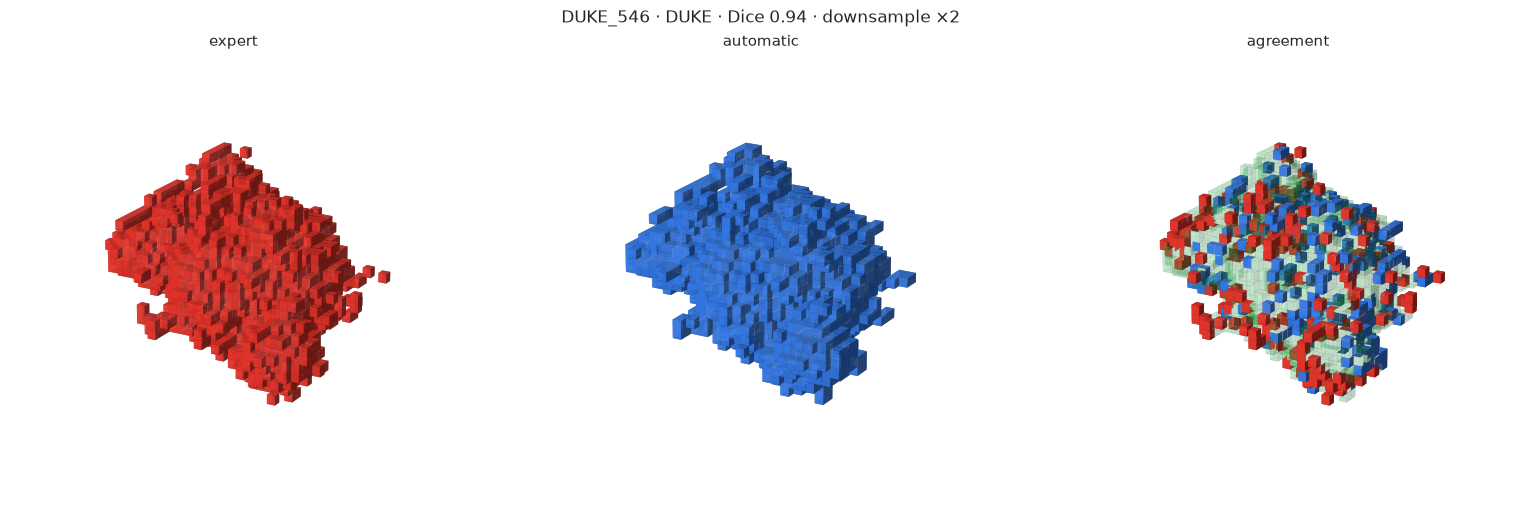

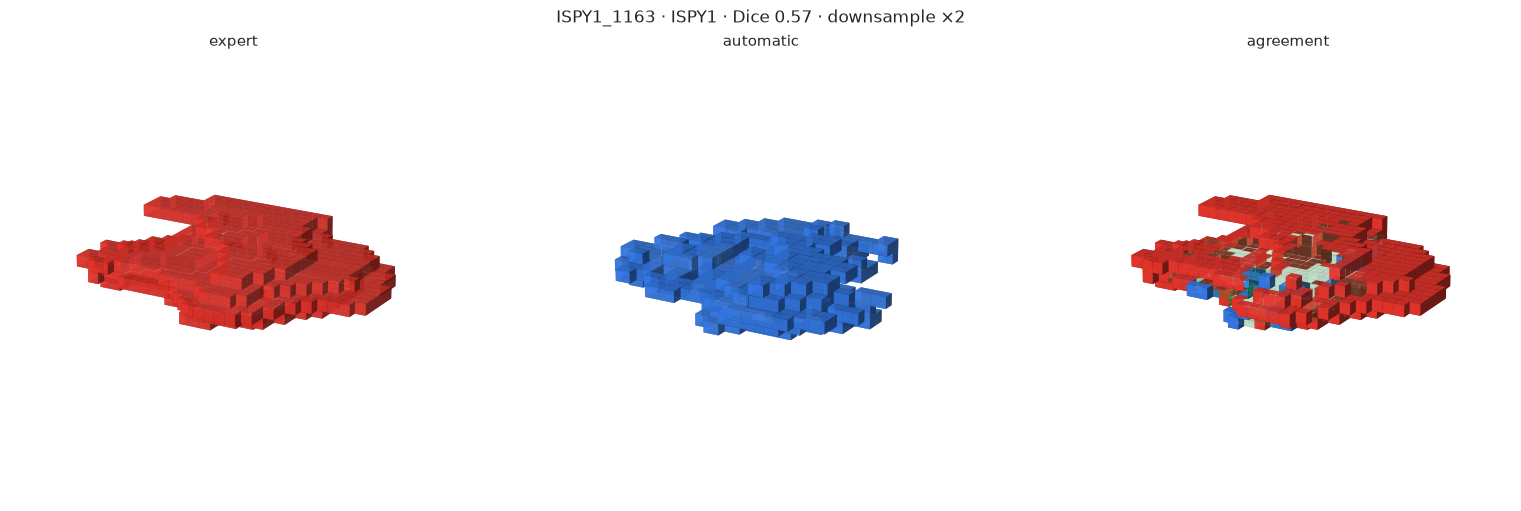

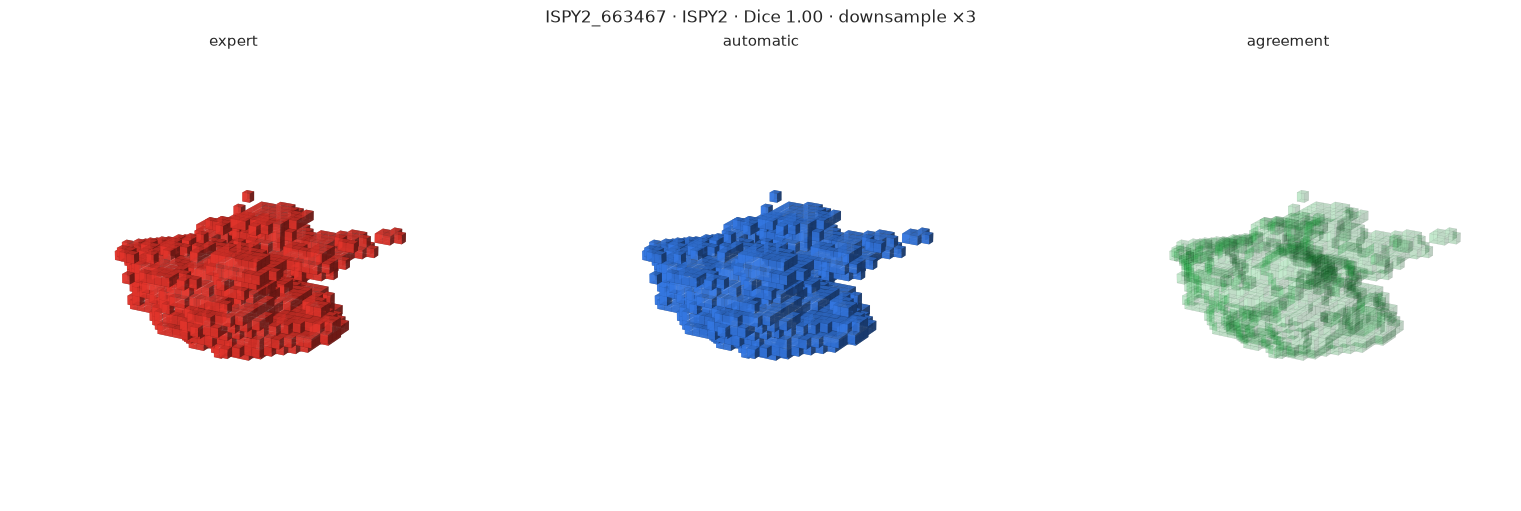

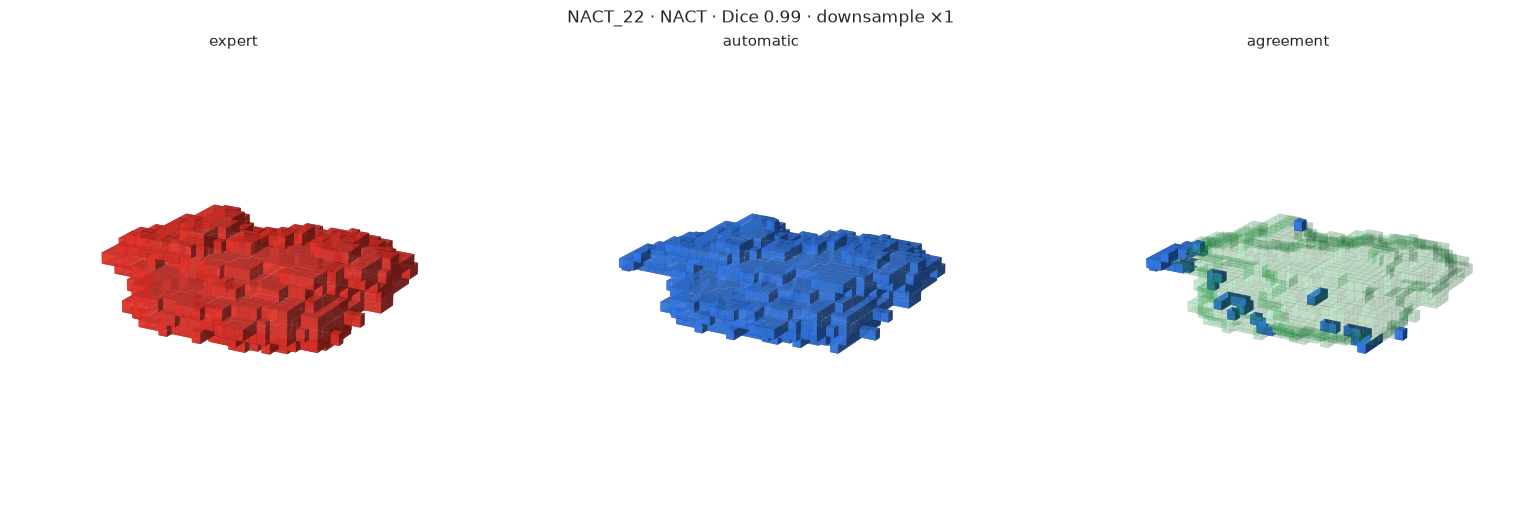

In [69]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3D projection)

GREEN, RED, BLUE = (0.18, 0.78, 0.33), (1.0, 0.23, 0.19), (0.23, 0.53, 1.0)

def _crop_down(e, a, max_side):
    """Crop both masks to their joint bounding box and downsample to <= max_side voxels per axis."""
    idx = np.argwhere(e | a)
    lo, hi = idx.min(0), idx.max(0) + 1
    e, a = e[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]], a[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]
    step = max(1, int(np.ceil(max(e.shape) / max_side)))
    return e[::step, ::step, ::step], a[::step, ::step, ::step], step

def _rgba(mask, rgb, alpha):
    c = np.zeros(mask.shape + (4,)); c[mask] = (*rgb, alpha); return c

def voxels_3d(pid, max_side=40, elev=20, azim=-60):
    """Expert | automatic | agreement, as 3D voxels from the same viewpoint."""
    _, e, a = load_masks(pid)
    d = dice(e, a)
    e, a, step = _crop_down(e, a, max_side)

    agree = _rgba(e & a, GREEN, 0.15)                    # agreement faint so errors stay visible
    agree[e & ~a] = (*RED, 0.95)                         # expert only = missed by model
    agree[~e & a] = (*BLUE, 0.95)                        # auto only = false positive

    panels = [("expert", e, _rgba(e, RED, 0.8)),
              ("automatic", a, _rgba(a, BLUE, 0.8)),
              ("agreement", e | a, agree)]
    fig = plt.figure(figsize=(16, 5.2))
    for i, (title, filled, colors) in enumerate(panels, 1):
        ax = fig.add_subplot(1, 3, i, projection="3d")
        ax.voxels(filled, facecolors=colors, edgecolor=(0, 0, 0, 0.08), linewidth=0.2)
        ax.view_init(elev=elev, azim=azim); ax.set_box_aspect(filled.shape); ax.set_axis_off()
        ax.set_title(title, fontsize=11)
    row = ms.set_index("patient_id").loc[pid]
    fig.suptitle(f"{pid} · {row.collection} · Dice {d:.2f} · downsample ×{step}", fontsize=12)
    plt.tight_layout(); plt.show()

for pid in cmp_picks:
    voxels_3d(pid)

In [70]:
# per-case numbers behind the 2D/3D comparisons above
rows = []
for pid in cmp_picks:
    r, e, a = load_masks(pid)
    vox_ml = float(np.prod(nib.load(r.seg_file).header.get_zooms()[:3])) / 1000
    inter, union = (e & a).sum(), (e | a).sum()
    rows.append({
        "patient_id": pid,
        "collection": r.collection,
        "expert [ml]": e.sum() * vox_ml,
        "auto [ml]": a.sum() * vox_ml,
        "volume diff [%]": (a.sum() - e.sum()) / e.sum() * 100,   # >0 auto larger, <0 auto smaller
        "Dice": 2 * inter / (e.sum() + a.sum()),
        "IoU": inter / union,
        "missed by auto [% of expert]": (e & ~a).sum() / e.sum() * 100,
        "extra in auto [% of auto]": (~e & a).sum() / a.sum() * 100,
    })
pd.DataFrame(rows).set_index("patient_id").round(2)

,collection,expert [ml],auto [ml],volume diff [%],Dice,IoU,missed by auto [% of expert],extra in auto [% of auto]
patient_id,,,,,,,,
DUKE_546,DUKE,18.11,17.81,-1.64,0.94,0.89,6.76,5.20
ISPY1_1163,ISPY1,11.46,5.00,-56.37,0.57,0.40,58.72,5.39
ISPY2_663467,ISPY2,97.58,97.58,0.00,1.00,1.00,0.00,0.00
NACT_22,NACT,2.83,2.90,2.59,0.99,0.97,0.00,2.52


**Findings (sample):** 3 of 4 cases agree closely (Dice 0.94–1.00); ISPY1_1163 shows the typical failure: auto **under-segments by 56%**, missing 59% of the expert tumour (necrotic core), with few false positives.
ISPY2_663467 is voxel-identical (Dice 1.00) → we check how often auto and expert masks are identical across the dataset.

In [71]:
def agreement_stats(row):
    """Expert vs automatic mask agreement for one case."""
    e = np.asanyarray(nib.load(row["seg_file"]).dataobj) > 0
    a = np.asanyarray(nib.load(row["auto_file"]).dataobj) > 0
    inter, es, as_ = (e & a).sum(), e.sum(), a.sum()
    return {"patient_id": row["patient_id"],
            "dice": 2 * inter / (es + as_) if es + as_ else 1.0,
            "iou": inter / (e | a).sum() if (e | a).any() else 1.0,
            "vol_diff_pct": (as_ - es) / es * 100 if es else np.nan,
            "missed_pct": (e & ~a).sum() / es * 100 if es else np.nan,
            "extra_pct": (~e & a).sum() / as_ * 100 if as_ else np.nan,
            "identical": bool(np.array_equal(e, a)),
            "auto_empty": as_ == 0}

AGREE_CACHE = OUT_DIR / "expert_vs_auto.csv"
if AGREE_CACHE.exists():
    agr = pd.read_csv(AGREE_CACHE)
else:
    with ProcessPoolExecutor(max_workers=8) as ex:
        agr = pd.DataFrame(list(tqdm(ex.map(agreement_stats, inv.to_dict("records"), chunksize=8), total=len(inv))))
    agr.to_csv(AGREE_CACHE, index=False)

agr = agr.merge(ms[["patient_id", "collection", "tumor_ml", "size_bin_eval"]], on="patient_id")
print("identical masks:", agr.identical.sum(), "| empty automatic masks:", agr.auto_empty.sum())

100%|██████████████████████████████████████████████████████████████████████████████| 1506/1506 [00:55<00:00, 27.10it/s]

identical masks: 33 | empty automatic masks: 0


In [72]:
def summarise(g):
    return pd.Series({
        "n": len(g),
        "Dice median": g.dice.median(),
        "Dice IQR": f"{g.dice.quantile(.25):.2f}–{g.dice.quantile(.75):.2f}",
        "Dice p5": g.dice.quantile(.05),
        "Dice mean": g.dice.mean(),
        "Dice < 0.5 [%]": (g.dice < .5).mean() * 100,
        "IoU median": g.iou.median(),
        "vol diff median [%]": g.vol_diff_pct.median(),
        "missed median [%]": g.missed_pct.median(),
        "extra median [%]": g.extra_pct.median(),
        "identical [%]": g.identical.mean() * 100,
    })

tbl_coll = agr.groupby("collection").apply(summarise).reindex(DATASETS)
tbl_coll.loc["all"] = summarise(agr)
tbl_coll.round(2)

,n,Dice median,Dice IQR,Dice p5,Dice mean,Dice < 0.5 [%],IoU median,vol diff median [%],missed median [%],extra median [%],identical [%]
collection,,,,,,,,,,,
DUKE,291,0.91,0.84–0.94,0.52,0.86,4.47,0.83,1.73,6.98,9.54,0.00
ISPY1,171,0.79,0.71–0.85,0.39,0.75,7.02,0.65,-9.18,22.80,9.99,0.00
ISPY2,980,0.92,0.80–0.97,0.33,0.84,9.49,0.85,2.94,2.40,7.22,3.27
NACT,64,0.90,0.76–0.96,0.19,0.78,17.19,0.83,13.00,0.80,12.81,1.56
all,1506,0.90,0.79–0.96,0.34,0.83,8.57,0.82,2.36,4.96,8.20,2.19


In [73]:
tbl_size = agr.groupby("size_bin_eval", observed=True).apply(summarise)
tbl_size.round(2)

,n,Dice median,Dice IQR,Dice p5,Dice mean,Dice < 0.5 [%],IoU median,vol diff median [%],missed median [%],extra median [%],identical [%]
size_bin_eval,,,,,,,,,,,
<5 ml,350,0.86,0.71–0.92,0.16,0.76,15.71,0.76,14.30,3.90,18.51,3.14
5–20 ml,713,0.91,0.81–0.96,0.36,0.84,7.71,0.84,2.12,4.78,7.53,1.40
>20 ml,443,0.91,0.80–0.97,0.53,0.86,4.29,0.84,-0.61,6.61,4.88,2.71


**Findings (all cases):** auto vs expert median Dice 0.90 (mean 0.83, 8.6% below 0.5); ISPY1 is worst (median 0.79, under-segments −9%, misses 23%), only 2% of masks are identical.
Errors depend on size: **small tumours (<5 ml) are over-segmented** (+14%, 16% failures), large ones slightly under-segmented.
These scores are optimistic (model saw all cases); the authors' cross-validated mean Dice of ~0.76 is the realistic reference for our baseline.

## 4. Frozen test set
A fixed held-out set, never used for training, tuning or the active-learning loop; we first check whether the official MAMA-MIA split is balanced enough to adopt.

In [58]:
# evaluation size bins (defined in section 3.1; recomputed here so this section runs on its own)
ms["size_bin_eval"] = pd.cut(ms.tumor_ml, [0, 5, 20, np.inf], labels=["<5 ml", "5–20 ml", ">20 ml"])

off = pd.read_csv(DATA_ROOT / "train_test_splits.csv")
off = (off.melt(var_name="split", value_name="patient_id").dropna()
          .assign(patient_id=lambda d: d.patient_id.str.upper(),
                  split=lambda d: d.split.str.replace("_split", "")))
off = off.merge(ms[["patient_id", "collection", "size_bin_eval", "tumor_ml"]], on="patient_id", how="left")

print("cases in official split:", len(off), "| unmatched:", off.collection.isna().sum(),
      "| duplicated IDs:", off.patient_id.duplicated().sum())

# share of each collection / size bin within train and test: should look alike if the split is balanced
by_coll = pd.crosstab(off.collection, off.split, normalize="columns").reindex(DATASETS) * 100
by_size = pd.crosstab(off.size_bin_eval, off.split, normalize="columns") * 100
counts  = off.split.value_counts().rename("cases").to_frame().T
display(counts, by_coll.round(1).add_suffix(" [%]"), by_size.round(1).add_suffix(" [%]"))

**Findings:** official split = 1,200 train / 306 test; size bins are balanced, collections deliberately are not (test over-represents DUKE and ISPY1).
**Decision:** adopt the official split for comparability; report per-collection and macro-averaged metrics (NACT has only ~17 test cases).

In [63]:
# freeze the split: written once, never overwritten
SPLIT_FILE = OUT_DIR / "frozen_split_official.csv"
split = off[["patient_id", "collection", "split", "tumor_ml", "size_bin_eval"]].sort_values(["split", "patient_id"])

if SPLIT_FILE.exists():
    prev = pd.read_csv(SPLIT_FILE)
    assert set(prev.patient_id[prev.split == "test"]) == set(split.patient_id[split.split == "test"]), "test set changed!"
    print("frozen split already exists and matches:", SPLIT_FILE)
else:
    split.to_csv(SPLIT_FILE, index=False)
    print("saved:", SPLIT_FILE)

print(pd.crosstab(split.collection, split.split, margins=True).reindex(DATASETS + ["All"]))

saved: /home/kacjan7732/zpi-eda/eda_out/frozen_split_official.csv
split       test  train   All
collection                   
DUKE          91    200   291
ISPY1         67    104   171
ISPY2        131    849   980
NACT          17     47    64
All          306   1200  1506


## 5. Summary
1,506 complete, clean cases (all masks binary and aligned) from 4 collections differing in vendor, plane (ISPY1/NACT sagittal) and slice thickness (1 vs 2–3 mm).
Tumours are log-normal (median ~11 ml), occupy ~0.2% of the volume (0.04% in DUKE) and are often heterogeneous; heart and vessels are hard negatives.

**Decisions for nnU-Net:** input = pre + 2 post-contrast phases (covers 100%; use phase counts from disk, not metadata); keep default Dice+CE and foreground sampling; no "keep largest component".
**Evaluation:** official frozen split (1,200 / 306), cross-validation on train only; report Dice per collection, per size bin (<5 / 5–20 / >20 ml), per slice thickness, macro-averaged, plus lesion-level detection.